In [1]:
from tensorflow import keras

model = keras.models.load_model('best—cnn_model.h5')

In [2]:
model.layers

[<Conv2D name=conv2d, built=True>,
 <Conv2D name=conv2d_1, built=True>,
 <MaxPooling2D name=max_pooling2d, built=True>,
 <Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dropout name=dropout, built=True>,
 <Dense name=dense_1, built=True>]

In [3]:
conv = model.layers[0]
print(conv.weights[0].shape, conv.weights[1].shape)

(3, 3, 1, 32) (32,)


In [4]:
import numpy

conv_weights = conv.weights[0].numpy()
print(conv_weights.mean(), conv_weights.std())

-0.018740395 0.2078137


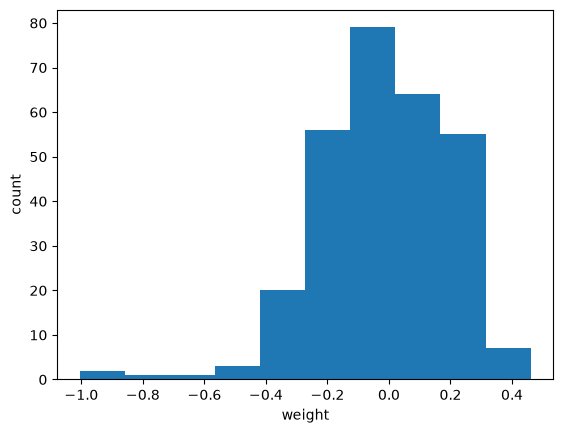

In [5]:
import os
import matplotlib.pyplot as plt

os.environ['KMP_DUPLICATION_LIB_OK'] = 'True'

plt.hist(conv_weights.reshape(-1, 1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

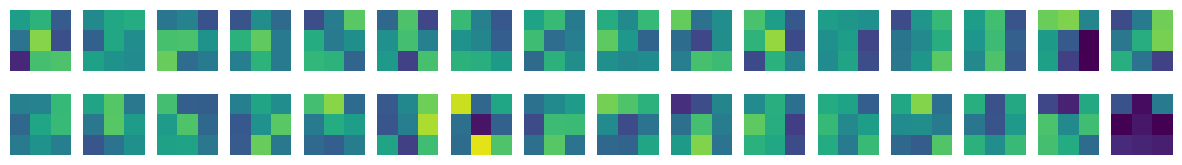

In [6]:
fig, axs = plt.subplots(2, 16, figsize=(15, 2))

for i in range(2):
    for j in range(16):
        axs[i, j].imshow(conv_weights[:, :, 0, i*16+j], vmin=-0.5, vmax=0.5)
        axs[i, j].axis('off')
        
plt.show()

In [7]:
no_training_model = keras.Sequential()

no_training_model.add(keras.Input(shape = (28, 28, 1)))
no_training_model.add(keras.layers.Conv2D(filters      = 32
                                         , kernel_size = (3,3)
                                         , padding     = 'same'
                                         , strides     = 1
                                         , activation  = 'relu'))

In [8]:
no_training_conv = no_training_model.layers[0]
print(no_training_conv.weights[0].shape)

(3, 3, 1, 32)


In [9]:
no_training_weights = no_training_conv.weights[0].numpy()
print(no_training_weights.mean(), no_training_weights.std())

-0.002493136 0.07917574


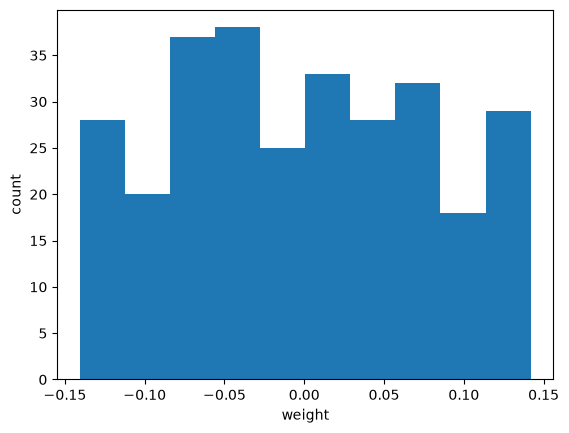

In [10]:
plt.hist(no_training_weights.reshape(-1, 1))
plt.xlabel('weight')
plt.ylabel('count')
plt.show()

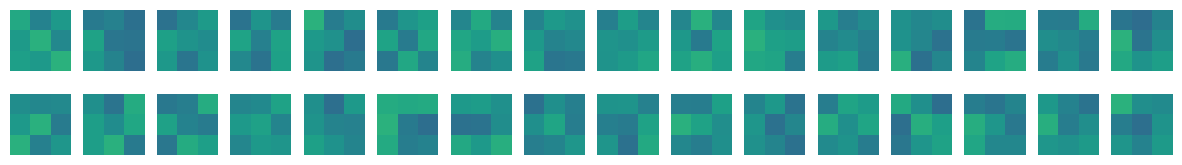

In [11]:
fig, axs = plt.subplots(2, 16, figsize=(15, 2))

for i in range(2):
    for j in range(16):
        axs[i, j].imshow(no_training_weights[:, :, 0, i*16+j], vmin=-0.5, vmax=0.5)
        axs[i, j].axis('off')
        
plt.show()